In [1]:
import warnings
warnings.filterwarnings("ignore")
import torch
from transformers import CLIPModel, CLIPProcessor

In [2]:
MODEL_NAME = "patrickjohncyh/fashion-clip"

In [3]:
model = CLIPModel.from_pretrained(MODEL_NAME)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)

model.eval()

print("FashionCLIP loaded successfully.")

Loading weights: 100%|██████████| 398/398 [00:01<00:00, 315.25it/s]


FashionCLIP loaded successfully.


In [4]:
print("Model name:", model.config._name_or_path)
print("Model commit:", model.config._commit_hash)

Model name: patrickjohncyh/fashion-clip


AttributeError: 'CLIPConfig' object has no attribute '_commit_hash'

In [5]:
from huggingface_hub import HfApi

MODEL_NAME = "patrickjohncyh/fashion-clip"

model_info = HfApi().model_info(MODEL_NAME)

print("Model Name:", model_info.id)
print("Model Revision:", model_info.sha)

Model Name: patrickjohncyh/fashion-clip
Model Revision: 7e3ba62ce16b379a1ab479346b66f192e76f51b7


In [ ]:
MODEL_NAME = "patrickjohncyh/fashion-clip"
MODEL_REVISION = "7e3ba62ce16b379a1ab479346b66f192e76f51b7"

print(typMODEL_REVISION))

# model = CLIPModel.from_pretrained(
#     MODEL_NAME,
#     revision=MODEL_REVISION
# )

# processor = CLIPProcessor.from_pretrained(
#     MODEL_NAME,
#     revision=MODEL_REVISION
# )

# model.eval()

<class 'str'>


In [4]:
print(type(model))
print(type(processor))
print("Text hidden size:", model.config.text_config.hidden_size)
print("Vision hidden size:", model.config.vision_config.hidden_size)
print("Embedding dimension:", model.config.projection_dim)

<class 'transformers.models.clip.modeling_clip.CLIPModel'>
<class 'transformers.models.clip.processing_clip.CLIPProcessor'>
Text hidden size: 512
Vision hidden size: 768
Embedding dimension: 512


In [ ]:
# # Reading User and Clothing Requirement Context

# import json

# with open("../data/context.json", "r", encoding="utf-8") as file:
#     context = json.load(file)

# print(context)

FileNotFoundError: [Errno 2] No such file or directory: '../data/context.json'

In [ ]:
# Using the reusable pipeline
# Change working directory to parent directory to import src
import os
os.chdir("..")

In [7]:
import src.context_builder as cb
context=cb.load_context("./data/context.json")

print(context)

{'destination': 'Seoul', 'season': 'winter', 'weather_clothing_requirements': {'outerwear': ['winter coat', 'puffer jacket'], 'top': ['sweater', 'knitwear'], 'bottom': ['long trousers'], 'footwear': ['closed shoes', 'boots'], 'properties': ['warm', 'insulated', 'layerable', 'weather-resistant']}, 'activity_style_requirements': {'sightseeing': ['casual', 'comfortable'], 'dinner': ['smart casual', 'polished']}, 'user_style': ['minimalist']}


In [ ]:
# os.getcwd()

'd:\\NUS AIS\\Intelligent Reasoning System Project - 1\\My Project Work - IRS\\IRS_Project\\stage2'

In [ ]:
# context_terms = []
# context_terms.append(context["destination"])

In [ ]:
# print(context_terms)

['Seoul']


In [ ]:

# wcr = context["weather_clothing_requirements"]

# context_terms.extend(wcr["outerwear"])
# context_terms.extend(wcr["top"])
# context_terms.extend(wcr["bottom"])
# context_terms.extend(wcr["footwear"])
# context_terms.extend(wcr["properties"])

In [ ]:
# print(context_terms)

['Seoul', 'winter coat', 'puffer jacket', 'sweater', 'knitwear', 'long trousers', 'closed shoes', 'boots', 'warm', 'insulated', 'layerable', 'weather-resistant']


In [ ]:
# asr = context["activity_style_requirements"]

# for activity, styles in asr.items():
#     context_terms.append(activity)
#     context_terms.extend(styles)

In [ ]:
# print(context_terms)

['Seoul', 'winter coat', 'puffer jacket', 'sweater', 'knitwear', 'long trousers', 'closed shoes', 'boots', 'warm', 'insulated', 'layerable', 'weather-resistant', 'sightseeing', 'casual', 'comfortable', 'dinner', 'smart casual', 'polished']


In [ ]:
# # Add Optional User Style (Used get here, so if the context does not contain style it will not throw error, instead add empty list [])
# context_terms.extend(context.get("user_style", []))
# print(context_terms)

['Seoul', 'winter coat', 'puffer jacket', 'sweater', 'knitwear', 'long trousers', 'closed shoes', 'boots', 'warm', 'insulated', 'layerable', 'weather-resistant', 'sightseeing', 'casual', 'comfortable', 'dinner', 'smart casual', 'polished', 'minimalist']


In [ ]:
# # Create Single String

# expanded_fashion_context = " ".join(term.strip() for term in context_terms if term.strip())

# print(expanded_fashion_context)
# print(type(expanded_fashion_context))

Seoul winter coat puffer jacket sweater knitwear long trousers closed shoes boots warm insulated layerable weather-resistant sightseeing casual comfortable dinner smart casual polished minimalist
<class 'str'>


In [ ]:
# Using Reusable Function Created in src
expanded_fashion_context=cb.build_expanded_fashion_context(context)

print(expanded_fashion_context)
print(type(expanded_fashion_context))

Seoul winter winter coat puffer jacket sweater knitwear long trousers closed shoes boots warm insulated layerable weather-resistant sightseeing casual comfortable dinner smart casual polished minimalist
<class 'str'>


In [12]:
from pathlib import Path

output_path = Path("./data/expanded_fashion_context.txt")

output_path.parent.mkdir(parents=True, exist_ok=True)

output_path.write_text(
    expanded_fashion_context,
    encoding="utf-8"
)

print("ExpandedFashionContext saved to:", output_path)

ExpandedFashionContext saved to: data\expanded_fashion_context.txt


In [10]:
os.getcwd()

'd:\\NUS AIS\\Intelligent Reasoning System Project - 1\\My Project Work - IRS\\IRS_Project\\stage2'

In [ ]:
## Experiment 1 — FashionCLIP Text Embeddings

## I can directly generate the Extended fashion context from src/context_builder

# Tokenize the ExpandedFashionContext
inputs = processor(
    text=[expanded_fashion_context],
    return_tensors="pt"
)

print(inputs)

{'input_ids': tensor([[49406, 13253,  2541,  7356,   755, 11636,  6164, 11455, 18745,  2839,
          1538, 23172,  4552,  4079,  7319,  3616, 42051,  7205, 18801,  2237,
           268, 17542, 34210, 10129,  8652,  2571,  4115, 10129, 21478, 26641,
         49407]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1]])}


In [29]:
# Inspect the tokens
input_ids = inputs["input_ids"]

print("Input IDs:")
print(input_ids)

print("\nShape:")
print(input_ids.shape)

Input IDs:
tensor([[49406, 13253,  2541,  7356,   755, 11636,  6164, 11455, 18745,  2839,
          1538, 23172,  4552,  4079,  7319,  3616, 42051,  7205, 18801,  2237,
           268, 17542, 34210, 10129,  8652,  2571,  4115, 10129, 21478, 26641,
         49407]])

Shape:
torch.Size([1, 31])


In [ ]:
# token_count = inputs["input_ids"].shape[1]
# print("Token count:", token_count)
# Already can see from above the token count is 31 tokens

# The maximum number of token positions the text encoder supports
print("Maximum token count:", model.config.text_config.max_position_embeddings)

Maximum token count: 77


In [61]:
with torch.no_grad():
    text_output = model.get_text_features(**inputs)

context_embedding = text_output.pooler_output

print(context_embedding.shape)

torch.Size([1, 512])


In [62]:
# Different Keys in the text_output result
print(text_output.keys())

odict_keys(['last_hidden_state', 'pooler_output'])


In [63]:
# Last Hidden State give vector embedding for each token
print(text_output.last_hidden_state.shape)

torch.Size([1, 31, 512])


In [64]:
# Pooler Output gives a single vector embedding output for the context, hence we use this to project to shared context embedding space
print(text_output.pooler_output.shape)

torch.Size([1, 512])


In [65]:
print("Pooled text shape:", pooled_text.shape) # the pooler_output is already passed through the appropriate projection layer.

Pooled text shape: torch.Size([1, 512])


In [66]:
# Normalize the Embedding
print("Norm of Context Embedding:", context_embedding.norm(dim=-1))

Norm of Context Embedding: tensor([7.3034])


In [67]:
context_embedding = context_embedding / context_embedding.norm(dim=-1, keepdim=True)
# Pytorch uses broadcasting so the norm is divided to each embedding vector value

In [68]:
print("Norm of Context Embedding after normalization:", context_embedding.norm(dim=-1))

Norm of Context Embedding after normalization: tensor([1.0000])


In [ ]:
# FashionCLIP Image Embeddings

from PIL import Image
from pathlib import Path

image_dir = Path("../test_images")

image_paths = [image_dir/f"image{i}.jpg" for i in range(1, 18)]

images = [Image.open(path).convert("RGB") for path in image_paths]

print("Number of images:", len(images))

Number of images: 17


In [50]:
# Image Preprocessing Using FashionClip
image_inputs = processor(
    images=images,
    return_tensors="pt"
)

In [51]:
print(image_inputs.keys())
print(image_inputs["pixel_values"].shape)

KeysView({'pixel_values': tensor([[[[ 2.0772e-01, -1.4264e-01, -4.6381e-01,  ...,  1.3318e+00,
            1.2880e+00,  1.3026e+00],
          [ 9.0934e-02, -1.1344e-01, -3.1782e-01,  ...,  1.2734e+00,
            1.3026e+00,  1.3318e+00],
          [-4.0451e-02, -3.6162e-01, -3.4702e-01,  ...,  1.2004e+00,
            1.2880e+00,  1.3172e+00],
          ...,
          [ 1.4340e+00,  1.4340e+00,  1.4340e+00,  ...,  1.5216e+00,
            1.4778e+00,  1.4632e+00],
          [ 1.4194e+00,  1.4194e+00,  1.4194e+00,  ...,  1.4778e+00,
            1.4486e+00,  1.4340e+00],
          [ 1.4194e+00,  1.4194e+00,  1.4194e+00,  ...,  1.3610e+00,
            1.3902e+00,  1.4194e+00]],

         [[ 9.4930e-01,  5.4409e-01,  1.0887e-01,  ...,  1.4596e+00,
            1.4145e+00,  1.4295e+00],
          [ 8.2924e-01,  5.4409e-01,  2.4394e-01,  ...,  1.3995e+00,
            1.4295e+00,  1.4596e+00],
          [ 6.9417e-01,  3.1897e-01,  2.2893e-01,  ...,  1.3245e+00,
            1.4295e+00,  1.4446e

In [ ]:
# Generate the 17 FashionCLIP image embeddings

with torch.no_grad():
    image_output = model.get_image_features(**image_inputs)
image_embeddings = image_output.pooler_output

print(image_embeddings.shape)

torch.Size([17, 512])


In [70]:
# L2-normalize each image independently

image_embeddings = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

In [71]:
print(image_embeddings.norm(dim=-1))

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [72]:
# Cosine Similarity between the context embedding and image embeddings (Embedded via FashionClip)
similarities = context_embedding @ image_embeddings.T
print(similarities.shape)

torch.Size([1, 17])


In [73]:
scores = similarities.squeeze(0)

ranked_indices = torch.argsort(scores,descending=True)

# printing the context again
print(expanded_fashion_context)
print()
for rank, idx_tensor in enumerate(ranked_indices, start=1):
    image_index = idx_tensor.item()
    print(rank, image_paths[image_index].name, scores[image_index].item())


Seoul winter coat puffer jacket sweater knitwear long trousers closed shoes boots warm insulated layerable weather-resistant sightseeing casual comfortable dinner smart casual polished minimalist

1 image5.jpg 0.31545209884643555
2 image7.jpg 0.301074743270874
3 image6.jpg 0.2965599000453949
4 image2.jpg 0.2946512699127197
5 image3.jpg 0.28990721702575684
6 image11.jpg 0.22428245842456818
7 image4.jpg 0.21158692240715027
8 image1.jpg 0.19954675436019897
9 image8.jpg 0.18154065310955048
10 image10.jpg 0.13934111595153809
11 image9.jpg 0.12052586674690247
12 image16.jpg 0.07105930894613266
13 image13.jpg 0.0695231705904007
14 image12.jpg 0.056382305920124054
15 image14.jpg 0.03426770120859146
16 image17.jpg -0.004654040560126305
17 image15.jpg -0.0546354316174984


TOP 5 MOST RELEVANT

Rank 1 | image5.jpg | Similarity: 0.3155


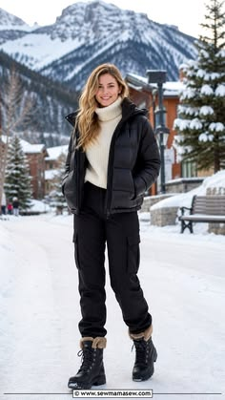

Rank 2 | image7.jpg | Similarity: 0.3011


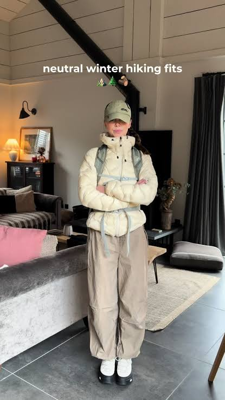

Rank 3 | image6.jpg | Similarity: 0.2966


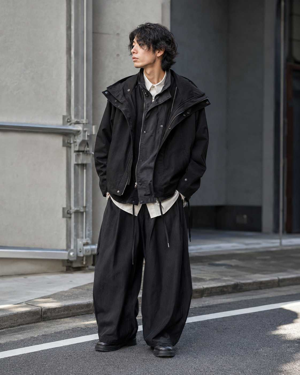

Rank 4 | image2.jpg | Similarity: 0.2947


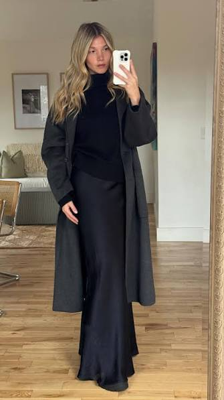

Rank 5 | image3.jpg | Similarity: 0.2899


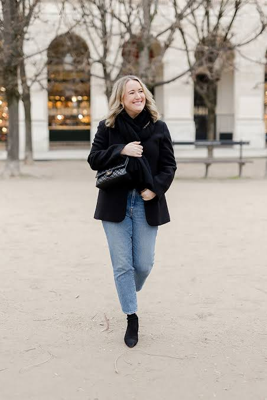

In [ ]:
# Display Top 3 Ranked Images

from IPython.display import display

DISPLAY_SIZE = (300, 400)

print("TOP 5 MOST RELEVANT\n")

for rank, idx in enumerate(ranked_indices[:5], start=1):
    image_index = idx.item()

    print(
        f"Rank {rank} | "
        f"{image_paths[image_index].name} | "
        f"Similarity: {scores[image_index].item():.4f}"
    )

    display_image = images[image_index].copy()
    display_image.thumbnail(DISPLAY_SIZE)

    display(display_image)

In [ ]:
### Similarity Issue Checking the Pipeline

In [ ]:
# print("Context shape:", context_embedding.shape)
# print("Image shape:", image_embeddings.shape)

# print(
#     "Context norm:",
#     context_embedding.norm(dim=-1)
# )

# print(
#     "Image norms:",
#     image_embeddings.norm(dim=-1)
# )

Context shape: torch.Size([1, 512])
Image shape: torch.Size([17, 512])
Context norm: tensor([1.])
Image norms: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
